In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd

/home/jiafzhou/.conda/envs/pyscenic/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
adata = ad.read_h5ad("/home/jiafzhou/GRN_org/dataset/adata_hvg_dmso-treatment-combined_scANVI_umap.h5ad", backed="r")

# cell type ratio

In [ ]:
adata.obs["celltype_scANVI_confident"].value_counts()

In [ ]:
drug_celltype = pd.crosstab(adata.obs["celltype_scANVI_confident"], adata.obs["drug"])

In [4]:
drug_celltype

drug,dmso,m108,m109,m110,m111,m112,m113,m114,m115,m116,...,m133,m134,m135,m137,m138,m139,m140,short-112,short-113,short-117
celltype_scANVI_confident,,,,,,,,,,,,,,,,,,,,,
NE_1,6239,4065,754,11246,6079,5243,6047,8918,7899,5922,...,1685,2373,3592,4194,5145,662,169,214,122,274
NE_2,13394,1134,177,2730,3401,4109,2775,3677,6907,198,...,401,8388,6441,10678,9709,1,26,5,5,8
NonTel_NE,7244,16492,1472,3106,5298,5534,3926,2811,2945,14925,...,11443,7156,2207,4444,2347,1489,54,252,53,262
RG,8659,8320,939,7010,5646,2592,10440,1978,7834,6339,...,8311,5359,2535,993,1936,19,2004,826,1257,1264
Di_RG,3845,3706,677,5232,1449,6789,4080,839,1962,3734,...,1357,1434,2610,326,1101,570,3558,344,597,430
Early_Neuron,2739,1307,799,3056,1888,2962,2519,4265,1605,5469,...,4593,1637,2289,667,4642,18,1693,421,455,451
VTel_Neuron,6036,4051,1380,8492,1574,1611,6275,2579,5357,3144,...,5261,4896,2244,4464,1637,0,371,155,1184,357
DTel_Neuron,4228,6028,3765,3022,2283,1562,4023,4119,2890,3418,...,1904,4157,2426,1306,3472,0,2483,1457,744,998
Glioblast,1599,3708,1159,1407,606,2659,904,7599,1027,5117,...,1481,2273,4425,661,271,107,1013,668,373,476


In [53]:
#downsample
selected_cell = []
for (drug, timepoint), x in adata.obs.groupby(["drug", "timepoint"], observed=True):
    if len(x) > 5000:
        selected_cell.extend(x.sample(n=5000, random_state=0).index.tolist())
    else:
        selected_cell.extend(x.index.tolist())

In [54]:
len(selected_cell)

479917

In [55]:
adata_ds = adata[selected_cell, :].copy()

In [56]:
adata_ds

AnnData object with n_obs × n_vars = 479917 × 5452
    obs: 'key_0', 'barcodes', 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'drug', 'timepoint', 'sublib', 'INT_ID', 'BARCODE', 'NUM.SNPS', 'NUM.READS', 'DROPLET.TYPE', 'BEST.GUESS', 'BEST.LLK', 'NEXT.GUESS', 'NEXT.LLK', 'DIFF.LLK.BEST.NEXT', 'BEST.POSTERIOR', 'SNG.POSTERIOR', 'SNG.BEST.GUESS', 'SNG.BEST.LLK', 'SNG.NEXT.GUESS', 'SNG.NEXT.LLK', 'SNG.ONLY.POSTERIOR', 'DBL.BEST.GUESS', 'DBL.BEST.LLK', 'DIFF.LLK.SNG.DBL', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'dataset', 'n_counts', 'histoneTarget', 'histoneColor', 'histoneFunction', 'targetComplex', 'expectedGEX', 'molecularTarget', 'drugName'

In [57]:
adata_ds_clean = adata_ds[adata_ds.obs["celltype_scANVI_confident"] != "Unknown", :].copy()

In [58]:
adata_ds_clean

AnnData object with n_obs × n_vars = 414856 × 5452
    obs: 'key_0', 'barcodes', 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'drug', 'timepoint', 'sublib', 'INT_ID', 'BARCODE', 'NUM.SNPS', 'NUM.READS', 'DROPLET.TYPE', 'BEST.GUESS', 'BEST.LLK', 'NEXT.GUESS', 'NEXT.LLK', 'DIFF.LLK.BEST.NEXT', 'BEST.POSTERIOR', 'SNG.POSTERIOR', 'SNG.BEST.GUESS', 'SNG.BEST.LLK', 'SNG.NEXT.GUESS', 'SNG.NEXT.LLK', 'SNG.ONLY.POSTERIOR', 'DBL.BEST.GUESS', 'DBL.BEST.LLK', 'DIFF.LLK.SNG.DBL', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'dataset', 'n_counts', 'histoneTarget', 'histoneColor', 'histoneFunction', 'targetComplex', 'expectedGEX', 'molecularTarget', 'drugName'

In [59]:
adata_ds_clean.write_h5ad("/home/jiafzhou/GRN_org/dataset/adata_hvg_dmso-treatment-combined_scANVI_umap_ds_clean.h5ad")

In [34]:
adata

AnnData object with n_obs × n_vars = 1531437 × 5452
    obs: 'key_0', 'barcodes', 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'drug', 'timepoint', 'sublib', 'INT_ID', 'BARCODE', 'NUM.SNPS', 'NUM.READS', 'DROPLET.TYPE', 'BEST.GUESS', 'BEST.LLK', 'NEXT.GUESS', 'NEXT.LLK', 'DIFF.LLK.BEST.NEXT', 'BEST.POSTERIOR', 'SNG.POSTERIOR', 'SNG.BEST.GUESS', 'SNG.BEST.LLK', 'SNG.NEXT.GUESS', 'SNG.NEXT.LLK', 'SNG.ONLY.POSTERIOR', 'DBL.BEST.GUESS', 'DBL.BEST.LLK', 'DIFF.LLK.SNG.DBL', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'dataset', 'n_counts', 'histoneTarget', 'histoneColor', 'histoneFunction', 'targetComplex', 'expectedGEX', 'molecularTarget', 'drugName

In [32]:
adata_ds_clean

AnnData object with n_obs × n_vars = 1312662 × 5452
    obs: 'key_0', 'barcodes', 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'drug', 'timepoint', 'sublib', 'INT_ID', 'BARCODE', 'NUM.SNPS', 'NUM.READS', 'DROPLET.TYPE', 'BEST.GUESS', 'BEST.LLK', 'NEXT.GUESS', 'NEXT.LLK', 'DIFF.LLK.BEST.NEXT', 'BEST.POSTERIOR', 'SNG.POSTERIOR', 'SNG.BEST.GUESS', 'SNG.BEST.LLK', 'SNG.NEXT.GUESS', 'SNG.NEXT.LLK', 'SNG.ONLY.POSTERIOR', 'DBL.BEST.GUESS', 'DBL.BEST.LLK', 'DIFF.LLK.SNG.DBL', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'dataset', 'n_counts', 'histoneTarget', 'histoneColor', 'histoneFunction', 'targetComplex', 'expectedGEX', 'molecularTarget', 'drugName

In [8]:
import matplotlib.pyplot as plt

In [5]:
cell_percent = drug_celltype.div(drug_celltype.sum(axis=0), axis=1)

In [6]:
cell_percent

drug,dmso,m108,m109,m110,m111,m112,m113,m114,m115,m116,...,m133,m134,m135,m137,m138,m139,m140,short-112,short-113,short-117
celltype_scANVI_confident,,,,,,,,,,,,,,,,,,,,,
NE_1,0.101309,0.062936,0.045345,0.202026,0.150866,0.115528,0.116769,0.165188,0.153531,0.088942,...,0.034249,0.049379,0.093059,0.120124,0.094830,0.152429,0.011742,0.035542,0.018549,0.044881
NE_2,0.217492,0.017557,0.010645,0.049043,0.084405,0.090541,0.053586,0.068109,0.134249,0.002974,...,0.008151,0.174543,0.166870,0.305837,0.178951,0.000230,0.001806,0.000830,0.000760,0.001310
NonTel_NE,0.117628,0.255338,0.088525,0.055797,0.131484,0.121940,0.075812,0.052068,0.057241,0.224156,...,0.232586,0.148907,0.057178,0.127284,0.043259,0.342851,0.003752,0.041854,0.008058,0.042916
RG,0.140605,0.128815,0.056471,0.125930,0.140120,0.057114,0.201599,0.036638,0.152267,0.095204,...,0.168926,0.111513,0.065675,0.028441,0.035683,0.004375,0.139234,0.137187,0.191121,0.207043
Di_RG,0.062435,0.057378,0.040714,0.093989,0.035961,0.149593,0.078786,0.015541,0.038135,0.056080,...,0.027582,0.029840,0.067618,0.009337,0.020293,0.131246,0.247204,0.057133,0.090771,0.070434
Early_Neuron,0.044476,0.020236,0.048051,0.054899,0.046856,0.065267,0.048642,0.079001,0.031196,0.082138,...,0.093356,0.034064,0.059302,0.019104,0.085559,0.004145,0.117627,0.069922,0.069180,0.073874
VTel_Neuron,0.098012,0.062720,0.082993,0.152553,0.039063,0.035498,0.121172,0.047771,0.104123,0.047219,...,0.106933,0.101879,0.058136,0.127857,0.030172,0.000000,0.025776,0.025743,0.180021,0.058477
DTel_Neuron,0.068654,0.093329,0.226425,0.054288,0.056659,0.034418,0.077685,0.076296,0.056172,0.051334,...,0.038700,0.086501,0.062851,0.037406,0.063994,0.000000,0.172514,0.241986,0.113121,0.163473
Glioblast,0.025965,0.057409,0.069702,0.025276,0.015039,0.058590,0.017456,0.140756,0.019962,0.076851,...,0.030102,0.047298,0.114640,0.018932,0.004995,0.024637,0.070381,0.110945,0.056713,0.077969


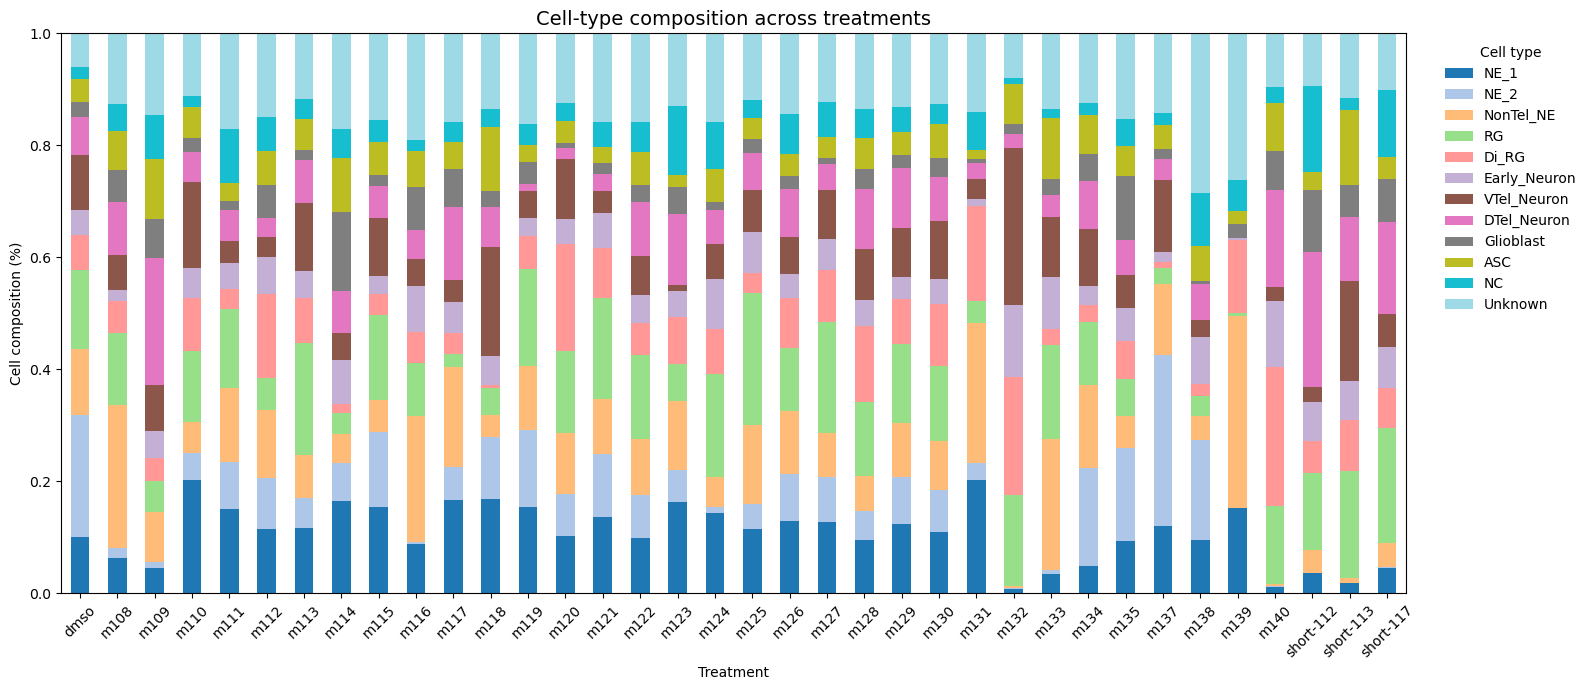

In [9]:
fig, ax = plt.subplots(
    figsize=(16, 7)
)

cell_percent.T.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")

ax.set_title(
    "Cell-type composition across treatments",
    fontsize=14,
)

ax.set_xlabel("Treatment")
ax.set_ylabel("Cell composition (%)")
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

plt.tight_layout()

In [10]:
drug_list = ["dmso", "m114", "m118", "m124", "m131", "m135"]

In [11]:
cell_percent_selected = cell_percent[drug_list]

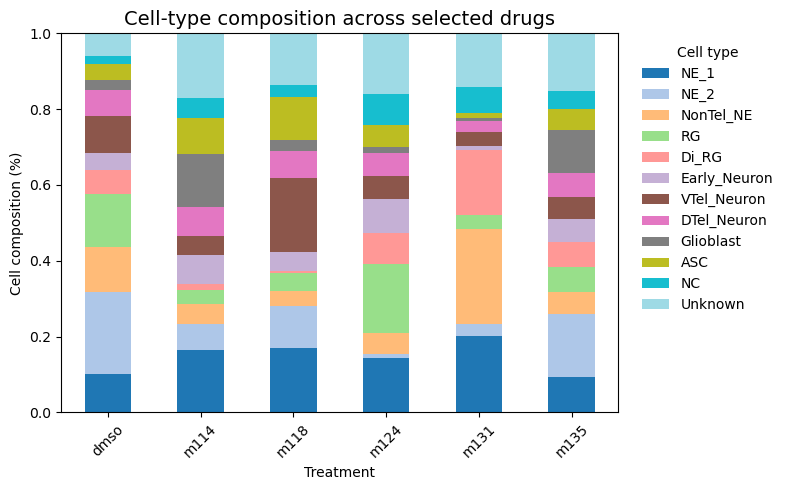

In [12]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

cell_percent_selected.T.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")

ax.set_title(
    "Cell-type composition across selected drugs",
    fontsize=14,
)

ax.set_xlabel("Treatment")
ax.set_ylabel("Cell composition (%)")
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

plt.tight_layout()

In [13]:
dmso_composition = cell_percent["dmso"]

composition_distance = (
    cell_percent
    .sub(dmso_composition, axis=0)
    .abs()
    .sum(axis=0)
    .div(2)
)

composition_distance = (
    composition_distance
    .sort_values(ascending=True)
)

composition_distance

drug
dmso         0.000000
m134         0.167720
m129         0.172825
m130         0.178977
m122         0.194212
m115         0.199694
m126         0.207801
m113         0.214230
m119         0.215206
m120         0.221372
m137         0.228913
m127         0.229181
m125         0.231305
m135         0.239930
m121         0.241198
m128         0.241365
m111         0.251311
m110         0.261972
m112         0.307192
m108         0.314687
m124         0.325781
m118         0.335115
m123         0.342616
m133         0.345792
m116         0.349978
m117         0.357899
m138         0.359922
short-117    0.388805
short-113    0.409060
m109         0.412787
m114         0.416045
short-112    0.449726
m131         0.469020
m132         0.486452
m140         0.492735
m139         0.579591
dtype: float64

In [14]:
drug_order = [
    "dmso"
] + [
    drug
    for drug in composition_distance.index
    if drug != "dmso"
]

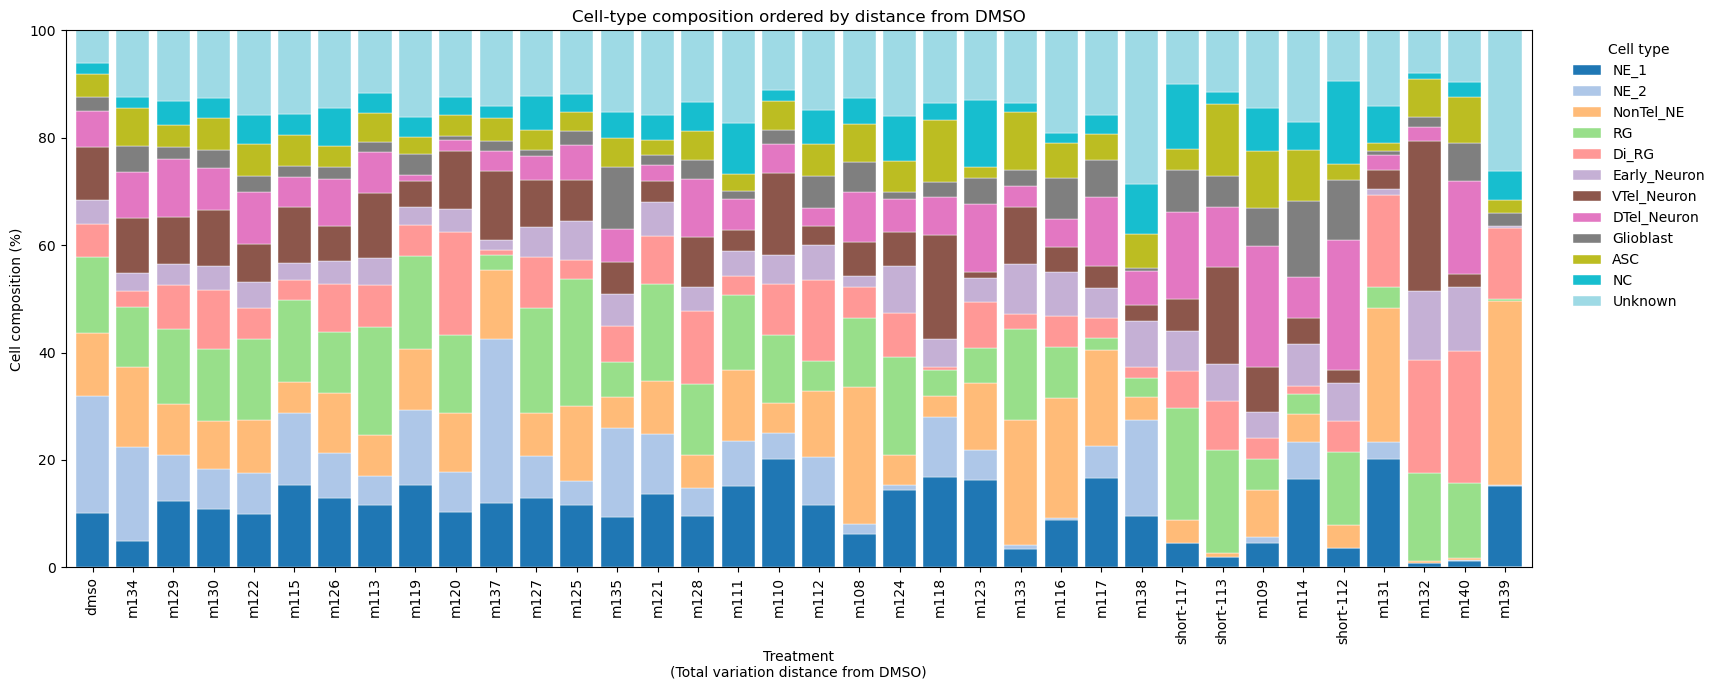

In [15]:
ordered_percentages = (
    cell_percent[drug_order] * 100
)

fig_width = max(
    12,
    len(drug_order) * 0.48,
)

fig, ax = plt.subplots(
    figsize=(fig_width, 7)
)

ordered_percentages.T.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.82,
    colormap="tab20",
    edgecolor="white",
    linewidth=0.3,
)

ax.set_title(
    "Cell-type composition ordered by distance from DMSO"
)

ax.set_xlabel(
    "Treatment\n(Total variation distance from DMSO)"
)

ax.set_ylabel("Cell composition (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Cell type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

plt.tight_layout()
plt.show()

https://www.nature.com/articles/s41592-025-02927-5/figures/2

# cell type depletion and enrichment responding to drug, along time d10, d30 and d120

In [3]:
adata_unknown = adata[adata.obs["celltype_scANVI_confident"] != "Unknown", :]

In [7]:
adata_unknown.obs["celltype_scANVI_confident"].unique()

['RG', 'VTel_Neuron', 'Di_RG', 'NonTel_NE', 'Early_Neuron', ..., 'NE_2', 'ASC', 'Glioblast', 'NE_1', 'DTel_Neuron']
Length: 11
Categories (11, object): ['NE_1' < 'NE_2' < 'NonTel_NE' < 'RG' ... 'DTel_Neuron' < 'Glioblast' < 'ASC' < 'NC']

In [4]:
drug_celltype_list = []

for t in adata_unknown.obs["timepoint"].unique():
    obs_t = adata_unknown.obs.loc[adata_unknown.obs["timepoint"] == t]

    drug_celltype_t = pd.crosstab(
        obs_t["celltype_scANVI_confident"],
        obs_t["drug"]
    )

    drug_celltype_t.columns = [
        f"{drug}-{t}" for drug in drug_celltype_t.columns
    ]

    drug_celltype_list.append(drug_celltype_t)

drug_celltype = (
    pd.concat(drug_celltype_list, axis=1)
    .fillna(0)
    .astype(int)
)

drug_celltype

,dmso-d30,m108-d30,m109-d30,m110-d30,m111-d30,m112-d30,m113-d30,m114-d30,m115-d30,m116-d30,...,m129-d10,m130-d10,m131-d10,m132-d10,m133-d10,m134-d10,m135-d10,m137-d10,m138-d10,m139-d10
celltype_scANVI_confident,,,,,,,,,,,,,,,,,,,,,
NE_1,403,474,74,459,180,285,504,297,307,484,...,5551,4510,7164,91,1505,1890,3226,3972,3645,615
NE_2,28,7,9,5,41,29,5,5,10,4,...,4429,3779,1169,6,377,8369,6438,10659,9698,1
NonTel_NE,259,591,382,151,336,465,275,877,417,1342,...,4603,4206,8602,4,11413,7028,2025,4439,1023,988
RG,7454,6500,382,5789,5408,2399,8878,1386,6544,3805,...,9,11,3,1,410,34,1,2,0,19
Di_RG,3219,3467,360,5054,1344,5960,3894,269,1797,3133,...,122,97,81,6,256,157,50,247,20,148
Early_Neuron,1370,859,323,1888,1534,1953,1386,3484,1203,2220,...,3,3,2,31,1,34,7,39,403,1
VTel_Neuron,944,613,5,56,645,1270,426,1084,724,588,...,0,0,0,0,0,0,0,0,3,0
DTel_Neuron,7,9,3,0,6,8,0,12,3,0,...,20,11,3,0,0,40,28,25,579,0
Glioblast,145,1721,153,416,296,1240,59,6221,449,25,...,22,20,0,4,127,527,133,384,20,0


In [5]:
drug_celltype = pd.crosstab([adata_unknown.obs["timepoint"], adata_unknown.obs["celltype_scANVI_confident"]],
                            adata_unknown.obs["drug"])

drug_celltype

drug                                  dmso   m108  m109   m110  m111  m112  \
timepoint celltype_scANVI_confident                                          
d10       NE_1                        5491   3189   403  10580  5809  4888   
          NE_2                       13294   1081   138   2666  3353  4078   
          NonTel_NE                   6858  15852  1077   2940  4941  4502   
          RG                            46     34    11      5    12     2   
          Di_RG                        164     15   271      8    60   101   
          Early_Neuron                   9      7     9      1    19     6   
          VTel_Neuron                    1      0     0      0     1     1   
          DTel_Neuron                   29      7     0      2    76    23   
          Glioblast                     65     47    99      7    60    88   
          ASC                           53     25   293      1   129    39   
          NC                            64    460   763    344  2739  1284   
d30       NE_1                         403    474    74    459   180   285   
          NE_2                          28      7     9      5    41    29   
          NonTel_NE                    259    591   382    151   336   465   
          RG                          7454   6500   382   5789  5408  2399   
          Di_RG                       3219   3467   360   5054  1344  5960   
          Early_Neuron                1370    859   323   1888  1534  1953   
          VTel_Neuron                  944    613     5     56   645  1270   
          DTel_Neuron                    7      9     3      0     6     8   
          Glioblast                    145   1721   153    416   296  1240   
          ASC                          121    859   126    130   401  1160   
          NC                          1082   2314   428    623  1100  1273   
d121      NE_1                         345    402   277    207    90    70   
          NE_2                          72     46    30     59     7     2   
          NonTel_NE                    127     49    13     15    21   567   
          RG                          1159   1786   546   1216   226   191   
          Di_RG                        462    224    46    170    45   728   
          Early_Neuron                1360    441   467   1167   335  1003   
          VTel_Neuron                 5091   3438  1375   8436   928   340   
          DTel_Neuron                 4192   6012  3762   3020  2201  1531   
          Glioblast                   1389   1940   907    984   250  1331   
          ASC                         2367   3681  1357   2903   754  1558   
          NC                           194    246   123    135    28   240   

drug                                 m113  m114  m115   m116  ...   m133  \
timepoint celltype_scANVI_confident                           ...          
d10       NE_1                       5349  8435  7371   4761  ...   1505   
          NE_2                       2725  3654  6824    194  ...    377   
          NonTel_NE                  3631  1918  2509  13231  ...  11413   
          RG                            2     4     4    293  ...    410   
          Di_RG                        13   384    64     95  ...    256   
          Early_Neuron                  0     3     4      7  ...      1   
          VTel_Neuron                   0     0     0      1  ...      0   
          DTel_Neuron                   3   107    28      0  ...      0   
          Glioblast                     4     3    47    102  ...    127   
          ASC                           8     6    42     13  ...    579   
          NC                          692  2065  1106    300  ...    580   
d30       NE_1                        504   297   307    484  ...     81   
          NE_2                          5     5    10      4  ...      2   
          NonTel_NE                   275   877   417   1342  ...      2   
          RG                         8878  1386  6544

In [6]:
total_cells = drug_celltype.groupby(level="timepoint").transform("sum") #get sum for each time point

cell_percent = drug_celltype.div(total_cells)

cell_percent

/tmp/ipykernel_4063048/2155583157.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  total_cells = drug_celltype.groupby(level="timepoint").transform("sum") #get sum for each time point


drug                                     dmso      m108      m109      m110  \
timepoint celltype_scANVI_confident                                           
d10       NE_1                       0.210593  0.153932  0.131527  0.639120   
          NE_2                       0.509857  0.052179  0.045039  0.161049   
          NonTel_NE                  0.263021  0.765169  0.351501  0.177601   
          RG                         0.001764  0.001641  0.003590  0.000302   
          Di_RG                      0.006290  0.000724  0.088446  0.000483   
          Early_Neuron               0.000345  0.000338  0.002937  0.000060   
          VTel_Neuron                0.000038  0.000000  0.000000  0.000000   
          DTel_Neuron                0.001112  0.000338  0.000000  0.000121   
          Glioblast                  0.002493  0.002269  0.032311  0.000423   
          ASC                        0.002033  0.001207  0.095627  0.000060   
          NC                         0.002455  0.022204  0.249021  0.020780   
d30       NE_1                       0.026809  0.027219  0.032962  0.031501   
          NE_2                       0.001863  0.000402  0.004009  0.000343   
          NonTel_NE                  0.017230  0.033938  0.170156  0.010363   
          RG                         0.495875  0.373263  0.170156  0.397296   
          Di_RG                      0.214143  0.199093  0.160356  0.346853   
          Early_Neuron               0.091139  0.049328  0.143875  0.129572   
          VTel_Neuron                0.062799  0.035202  0.002227  0.003843   
          DTel_Neuron                0.000466  0.000517  0.001336  0.000000   
          Glioblast                  0.009646  0.098829  0.068151  0.028550   
          ASC                        0.008049  0.049328  0.056125  0.008922   
          NC                         0.071980  0.132882  0.190646  0.042756   
d121      NE_1                       0.020587  0.022009  0.031113  0.011304   
          NE_2                       0.004296  0.002518  0.003370  0.003222   
          NonTel_NE                  0.007578  0.002683  0.001460  0.000819   
          RG                         0.069161  0.097783  0.061328  0.066405   
          Di_RG                      0.027569  0.012264  0.005167  0.009284   
          Early_Neuron               0.081155  0.024145  0.052454  0.063729   
          VTel_Neuron                0.303795  0.188229  0.154442  0.460682   
          DTel_Neuron                0.250149  0.329154  0.422554  0.164919   
          Glioblast                  0.082886  0.106214  0.101876  0.053735   
          ASC                        0.141246  0.201533  0.152421  0.158530   
          NC                         0.011577  0.013468  0.013816  0.007372   

drug                                     m111      m112      m113      m114  \
timepoint celltype_scANVI_confident                                           
d10       NE_1                       0.337752  0.325606  0.430434  0.508776   
          NE_2                       0.194953  0.271649  0.219281  0.220399   
          NonTel_NE                  0.287284  0.299893  0.292186  0.115689   
          RG                         0.000698  0.000133  0.000161  0.000241   
          Di_RG                      0.003489  0.006728  0.001046  0.023162   
          Early_Neuron               0.001105  0.000400  0.000000  0.000181   
          VTel_Neuron                0.000058  0.000067  0.000000  0.000000   
          DTel_Neuron                0.004419  0.001532  0.000241  0.006454   
          Glioblast                  0.003489  0.005862  0.000322  0.000181   
          ASC                        0.007500  0.002598  0.000644  0.000362   
          NC                         0.159253  0.085532  0.055685  0.124555   
d30       NE_1                       0.015942  0.017766  0.029842  0.017454   
          NE_2                       0.003631  0.001808  0.000296  0.000294   
          NonTel_NE                  0.029758  0.

In [7]:
drug_celltype.groupby(level="timepoint").transform("sum")

/tmp/ipykernel_4063048/695821551.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  drug_celltype.groupby(level="timepoint").transform("sum")


drug                                  dmso   m108  m109   m110   m111   m112  \
timepoint celltype_scANVI_confident                                            
d10       NE_1                       26074  20717  3064  16554  17199  15012   
          NE_2                       26074  20717  3064  16554  17199  15012   
          NonTel_NE                  26074  20717  3064  16554  17199  15012   
          RG                         26074  20717  3064  16554  17199  15012   
          Di_RG                      26074  20717  3064  16554  17199  15012   
          Early_Neuron               26074  20717  3064  16554  17199  15012   
          VTel_Neuron                26074  20717  3064  16554  17199  15012   
          DTel_Neuron                26074  20717  3064  16554  17199  15012   
          Glioblast                  26074  20717  3064  16554  17199  15012   
          ASC                        26074  20717  3064  16554  17199  15012   
          NC                         26074  20717  3064  16554  17199  15012   
d30       NE_1                       15032  17414  2245  14571  11291  16042   
          NE_2                       15032  17414  2245  14571  11291  16042   
          NonTel_NE                  15032  17414  2245  14571  11291  16042   
          RG                         15032  17414  2245  14571  11291  16042   
          Di_RG                      15032  17414  2245  14571  11291  16042   
          Early_Neuron               15032  17414  2245  14571  11291  16042   
          VTel_Neuron                15032  17414  2245  14571  11291  16042   
          DTel_Neuron                15032  17414  2245  14571  11291  16042   
          Glioblast                  15032  17414  2245  14571  11291  16042   
          ASC                        15032  17414  2245  14571  11291  16042   
          NC                         15032  17414  2245  14571  11291  16042   
d121      NE_1                       16758  18265  8903  18312   4885   7561   
          NE_2                       16758  18265  8903  18312   4885   7561   
          NonTel_NE                  16758  18265  8903  18312   4885   7561   
          RG                         16758  18265  8903  18312   4885   7561   
          Di_RG                      16758  18265  8903  18312   4885   7561   
          Early_Neuron               16758  18265  8903  18312   4885   7561   
          VTel_Neuron                16758  18265  8903  18312   4885   7561   
          DTel_Neuron                16758  18265  8903  18312   4885   7561   
          Glioblast                  16758  18265  8903  18312   4885   7561   
          ASC                        16758  18265  8903  18312   4885   7561   
          NC                         16758  18265  8903  18312   4885   7561   

drug                                  m113   m114   m115   m116  ...   m133  \
timepoint celltype_scANVI_confident                              ...          
d10       NE_1                       12427  16579  17999  18997  ...  15248   
          NE_2                       12427  16579  17999  18997  ...  15248   
          NonTel_NE                  12427  16579  17999  18997  ...  15248   
          RG                         12427  16579  17999  18997  ...  15248   
          Di_RG                      12427  16579  17999  18997  ...  15248   
          Early_Neuron               12427  16579  17999  18997  ...  15248   
          VTel_Neuron                12427  16579  17999  18997  ...  15248   
          DTel_Neuron                12427  16579  17999  18997  ...  15248   
          Glioblast                  12427  16579  17999  18997  ...  15248   
          ASC                        12427  16579  17999  18997  ...  15248   
          NC                         12427  16579  17999  18997  ...  15248   
d30       NE_1                       16889  17016  12658  13090  ...  16566   
          NE_2                       16889  17016  12658  13090  ...  16566   
          NonT

In [8]:
cell_percent_delta = cell_percent.copy()
for drug in cell_percent_delta.columns:
    cell_percent_delta[drug] = cell_percent[drug]-cell_percent["dmso"]

In [9]:
cell_percent_delta

drug                                 dmso      m108      m109      m110  \
timepoint celltype_scANVI_confident                                       
d10       NE_1                        0.0 -0.056661 -0.079066  0.428528   
          NE_2                        0.0 -0.457677 -0.464817 -0.348808   
          NonTel_NE                   0.0  0.502148  0.088481 -0.085420   
          RG                          0.0 -0.000123  0.001826 -0.001462   
          Di_RG                       0.0 -0.005566  0.082157 -0.005807   
          Early_Neuron                0.0 -0.000007  0.002592 -0.000285   
          VTel_Neuron                 0.0 -0.000038 -0.000038 -0.000038   
          DTel_Neuron                 0.0 -0.000774 -0.001112 -0.000991   
          Glioblast                   0.0 -0.000224  0.029818 -0.002070   
          ASC                         0.0 -0.000826  0.093594 -0.001972   
          NC                          0.0  0.019749  0.246566  0.018326   
d30       NE_1                        0.0  0.000410  0.006153  0.004691   
          NE_2                        0.0 -0.001461  0.002146 -0.001520   
          NonTel_NE                   0.0  0.016708  0.152926 -0.006867   
          RG                          0.0 -0.122613 -0.325720 -0.098579   
          Di_RG                       0.0 -0.015050 -0.053787  0.132710   
          Early_Neuron                0.0 -0.041811  0.052736  0.038434   
          VTel_Neuron                 0.0 -0.027598 -0.060572 -0.058956   
          DTel_Neuron                 0.0  0.000051  0.000871 -0.000466   
          Glioblast                   0.0  0.089182  0.058505  0.018904   
          ASC                         0.0  0.041279  0.048075  0.000872   
          NC                          0.0  0.060902  0.118666 -0.029224   
d121      NE_1                        0.0  0.001422  0.010526 -0.009283   
          NE_2                        0.0 -0.001778 -0.000927 -0.001075   
          NonTel_NE                   0.0 -0.004896 -0.006118 -0.006759   
          RG                          0.0  0.028622 -0.007833 -0.002756   
          Di_RG                       0.0 -0.015305 -0.022402 -0.018285   
          Early_Neuron                0.0 -0.057011 -0.028701 -0.017427   
          VTel_Neuron                 0.0 -0.115566 -0.149353  0.156886   
          DTel_Neuron                 0.0  0.079005  0.172405 -0.085230   
          Glioblast                   0.0  0.023328  0.018990 -0.029151   
          ASC                         0.0  0.060287  0.011175  0.017284   
          NC                          0.0  0.001892  0.002239 -0.004204   

drug                                     m111      m112      m113      m114  \
timepoint celltype_scANVI_confident                                           
d10       NE_1                       0.127159  0.115013  0.219841  0.298183   
          NE_2                      -0.314903 -0.238207 -0.290576 -0.289457   
          NonTel_NE                  0.024264  0.036873  0.029166 -0.147332   
          RG                        -0.001066 -0.001631 -0.001603 -0.001523   
          Di_RG                     -0.002801  0.000438 -0.005244  0.016872   
          Early_Neuron               0.000760  0.000055 -0.000345 -0.000164   
          VTel_Neuron                0.000020  0.000028 -0.000038 -0.000038   
          DTel_Neuron                0.003307  0.000420 -0.000871  0.005342   
          Glioblast                  0.000996  0.003369 -0.002171 -0.002312   
          ASC                        0.005468  0.000565 -0.001389 -0.001671   
          NC                         0.156799  0.083077  0.053231  0.122101   
d30       NE_1                      -0.010868 -0.009044  0.003032 -0.009355   
          NE_2                       0.001769 -0.000055 -0.001567 -0.001569   
          NonTel_NE                  0.012528  0.011757 -0.000947  0.034310   
          RG                        -0.016910 -0.346331  0.029792 -0.414423   
          Di_RG                

In [10]:
cell_percent_delta_clean = cell_percent_delta.iloc[:, 1:]
cell_percent_delta_clean

drug                                     m108      m109      m110      m111  \
timepoint celltype_scANVI_confident                                           
d10       NE_1                      -0.056661 -0.079066  0.428528  0.127159   
          NE_2                      -0.457677 -0.464817 -0.348808 -0.314903   
          NonTel_NE                  0.502148  0.088481 -0.085420  0.024264   
          RG                        -0.000123  0.001826 -0.001462 -0.001066   
          Di_RG                     -0.005566  0.082157 -0.005807 -0.002801   
          Early_Neuron              -0.000007  0.002592 -0.000285  0.000760   
          VTel_Neuron               -0.000038 -0.000038 -0.000038  0.000020   
          DTel_Neuron               -0.000774 -0.001112 -0.000991  0.003307   
          Glioblast                 -0.000224  0.029818 -0.002070  0.000996   
          ASC                       -0.000826  0.093594 -0.001972  0.005468   
          NC                         0.019749  0.246566  0.018326  0.156799   
d30       NE_1                       0.000410  0.006153  0.004691 -0.010868   
          NE_2                      -0.001461  0.002146 -0.001520  0.001769   
          NonTel_NE                  0.016708  0.152926 -0.006867  0.012528   
          RG                        -0.122613 -0.325720 -0.098579 -0.016910   
          Di_RG                     -0.015050 -0.053787  0.132710 -0.095110   
          Early_Neuron              -0.041811  0.052736  0.038434  0.044722   
          VTel_Neuron               -0.027598 -0.060572 -0.058956 -0.005674   
          DTel_Neuron                0.000051  0.000871 -0.000466  0.000066   
          Glioblast                  0.089182  0.058505  0.018904  0.016569   
          ASC                        0.041279  0.048075  0.000872  0.027466   
          NC                         0.060902  0.118666 -0.029224  0.025443   
d121      NE_1                       0.001422  0.010526 -0.009283 -0.002163   
          NE_2                      -0.001778 -0.000927 -0.001075 -0.002863   
          NonTel_NE                 -0.004896 -0.006118 -0.006759 -0.003280   
          RG                         0.028622 -0.007833 -0.002756 -0.022897   
          Di_RG                     -0.015305 -0.022402 -0.018285 -0.018357   
          Early_Neuron              -0.057011 -0.028701 -0.017427 -0.012578   
          VTel_Neuron               -0.115566 -0.149353  0.156886 -0.113826   
          DTel_Neuron                0.079005  0.172405 -0.085230  0.200414   
          Glioblast                  0.023328  0.018990 -0.029151 -0.031709   
          ASC                        0.060287  0.011175  0.017284  0.013104   
          NC                         0.001892  0.002239 -0.004204 -0.005845   

drug                                     m112      m113      m114      m115  \
timepoint celltype_scANVI_confident                                           
d10       NE_1                       0.115013  0.219841  0.298183  0.198930   
          NE_2                      -0.238207 -0.290576 -0.289457 -0.130724   
          NonTel_NE                  0.036873  0.029166 -0.147332 -0.123624   
          RG                        -0.001631 -0.001603 -0.001523 -0.001542   
          Di_RG                      0.000438 -0.005244  0.016872 -0.002734   
          Early_Neuron               0.000055 -0.000345 -0.000164 -0.000123   
          VTel_Neuron                0.000028 -0.000038 -0.000038 -0.000038   
          DTel_Neuron                0.000420 -0.000871  0.005342  0.000443   
          Glioblast                  0.003369 -0.002171 -0.002312  0.000118   
          ASC                        0.000565 -0.001389 -0.001671  0.000301   
          NC                         0.083077  0.053231  0.122101  0.058993   
d30       NE_1                      -0.009044  0.003032 -0.009355 -0.002556   
          NE_2                      -0.000055 -0.001567 -0.001569 -0.001073   
          NonTel_NE                  0.011757 -0.

In [11]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd

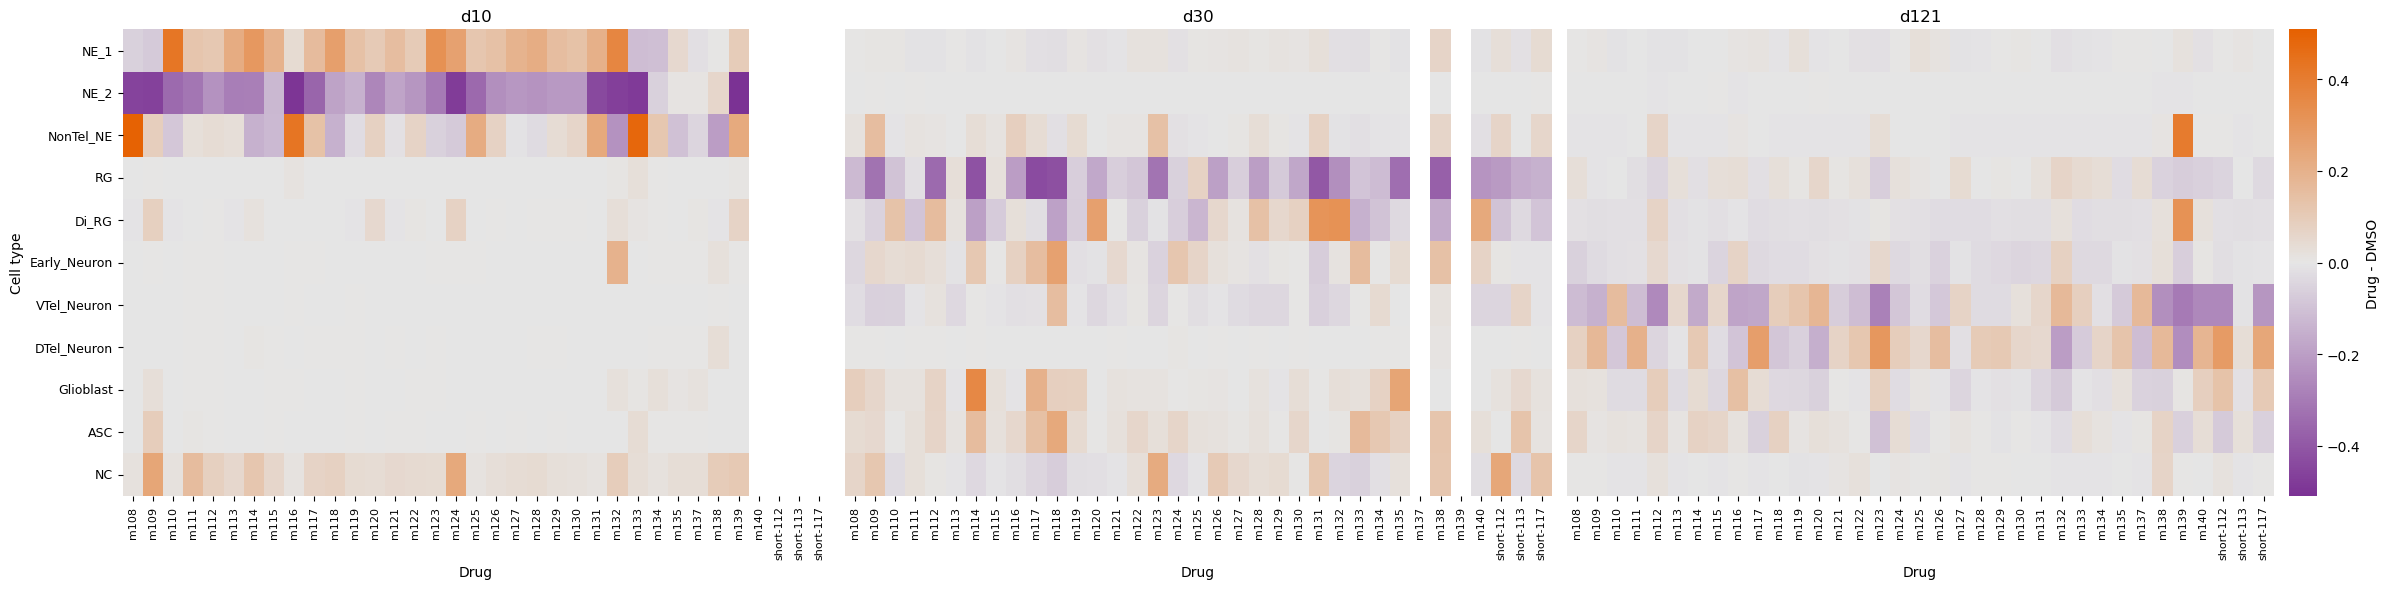

In [12]:
plot_data = cell_percent_delta_clean.replace([np.inf, -np.inf], np.nan)


timepoints = ["d10", "d30", "d121"]
celltype_order = (
    plot_data.index
    .get_level_values("celltype_scANVI_confident")
    .unique()
)

# All panels use the same symmetric color scale.
limit = max(
    np.nanmax(np.abs(plot_data.to_numpy(dtype=float))),
    1e-12,
)


cmap = LinearSegmentedColormap.from_list(
    "figure2a_style",
    ["#7B3294", "#E6E6E6", "#E66101"],
    N=257,
)

cmap.set_bad("#FFFFFF")  # Missing values are white.


fig, axes = plt.subplots(
    1, 4,
    figsize=(24, 6),
    gridspec_kw={"width_ratios": [1, 1, 1, 0.04]},
)

for i, timepoint in enumerate(timepoints):
    data = (
        plot_data
        .xs(timepoint, level="timepoint")
        .reindex(celltype_order)
    )

    sns.heatmap(
        data,
        ax=axes[i],
        cmap=cmap,
        center=0,
        vmin=-limit,
        vmax=limit,
        yticklabels=(i == 0),
        xticklabels=True,
        cbar=(i == 2),
        cbar_ax=axes[3] if i == 2 else None,
        cbar_kws={"label": "Drug - DMSO"},
    )



    axes[i].set_title(timepoint)
    axes[i].set_xlabel("Drug")
    axes[i].set_ylabel("Cell type" if i == 0 else "")
    axes[i].tick_params(axis="x", labelrotation=90, labelsize=8)
    axes[i].tick_params(axis="y", labelrotation=0, labelsize=9)

plt.tight_layout()
plt.show()

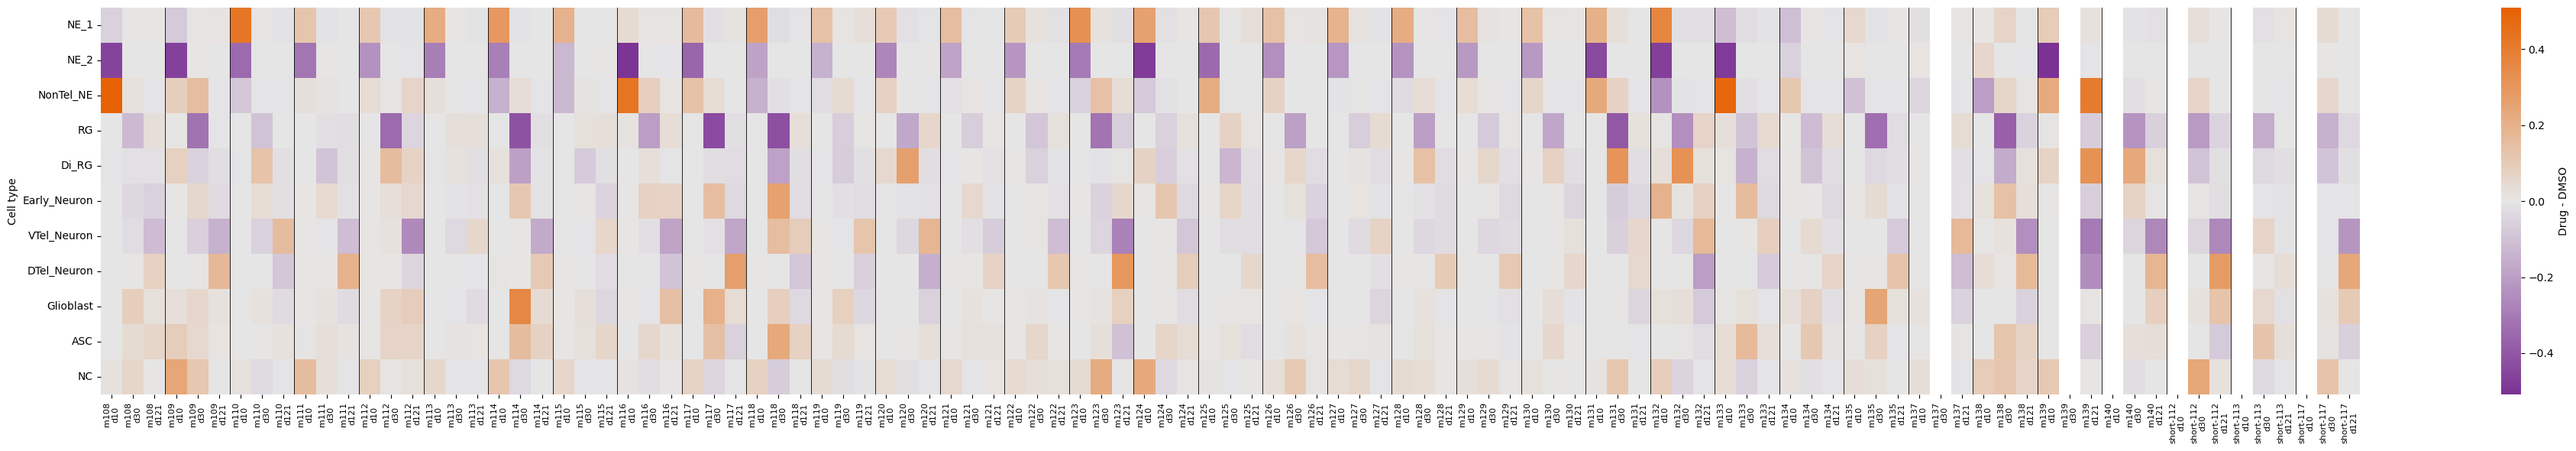

In [13]:
drugs = cell_percent_delta_clean.columns.tolist()

# Move timepoint from the row index to the columns.
plot_data = cell_percent_delta_clean.unstack("timepoint")

plot_data = plot_data.reindex(
    index=cell_percent_delta_clean.index.get_level_values(
        "celltype_scANVI_confident"
    ).unique(),
    columns=pd.MultiIndex.from_product([drugs, timepoints]),
)

limit = max(
    np.nanmax(np.abs(plot_data.to_numpy(dtype=float))),
    1e-12,
)

fig, ax = plt.subplots(
    figsize=(max(12, len(drugs) * 1.1), 6)
)

sns.heatmap(
    plot_data,
    cmap=cmap,
    center=0,
    vmin=-limit,
    vmax=limit,
    xticklabels=[
        f"{drug}\n{timepoint}"
        for drug, timepoint in plot_data.columns
    ],
    cbar_kws={"label": "Drug - DMSO"},
    ax=ax,
)

# Separate adjacent drugs.
for x in range(3, plot_data.shape[1], 3):
    ax.axvline(x, color="black", linewidth=0.6)



ax.set_xlabel("")
ax.set_ylabel("Cell type")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()

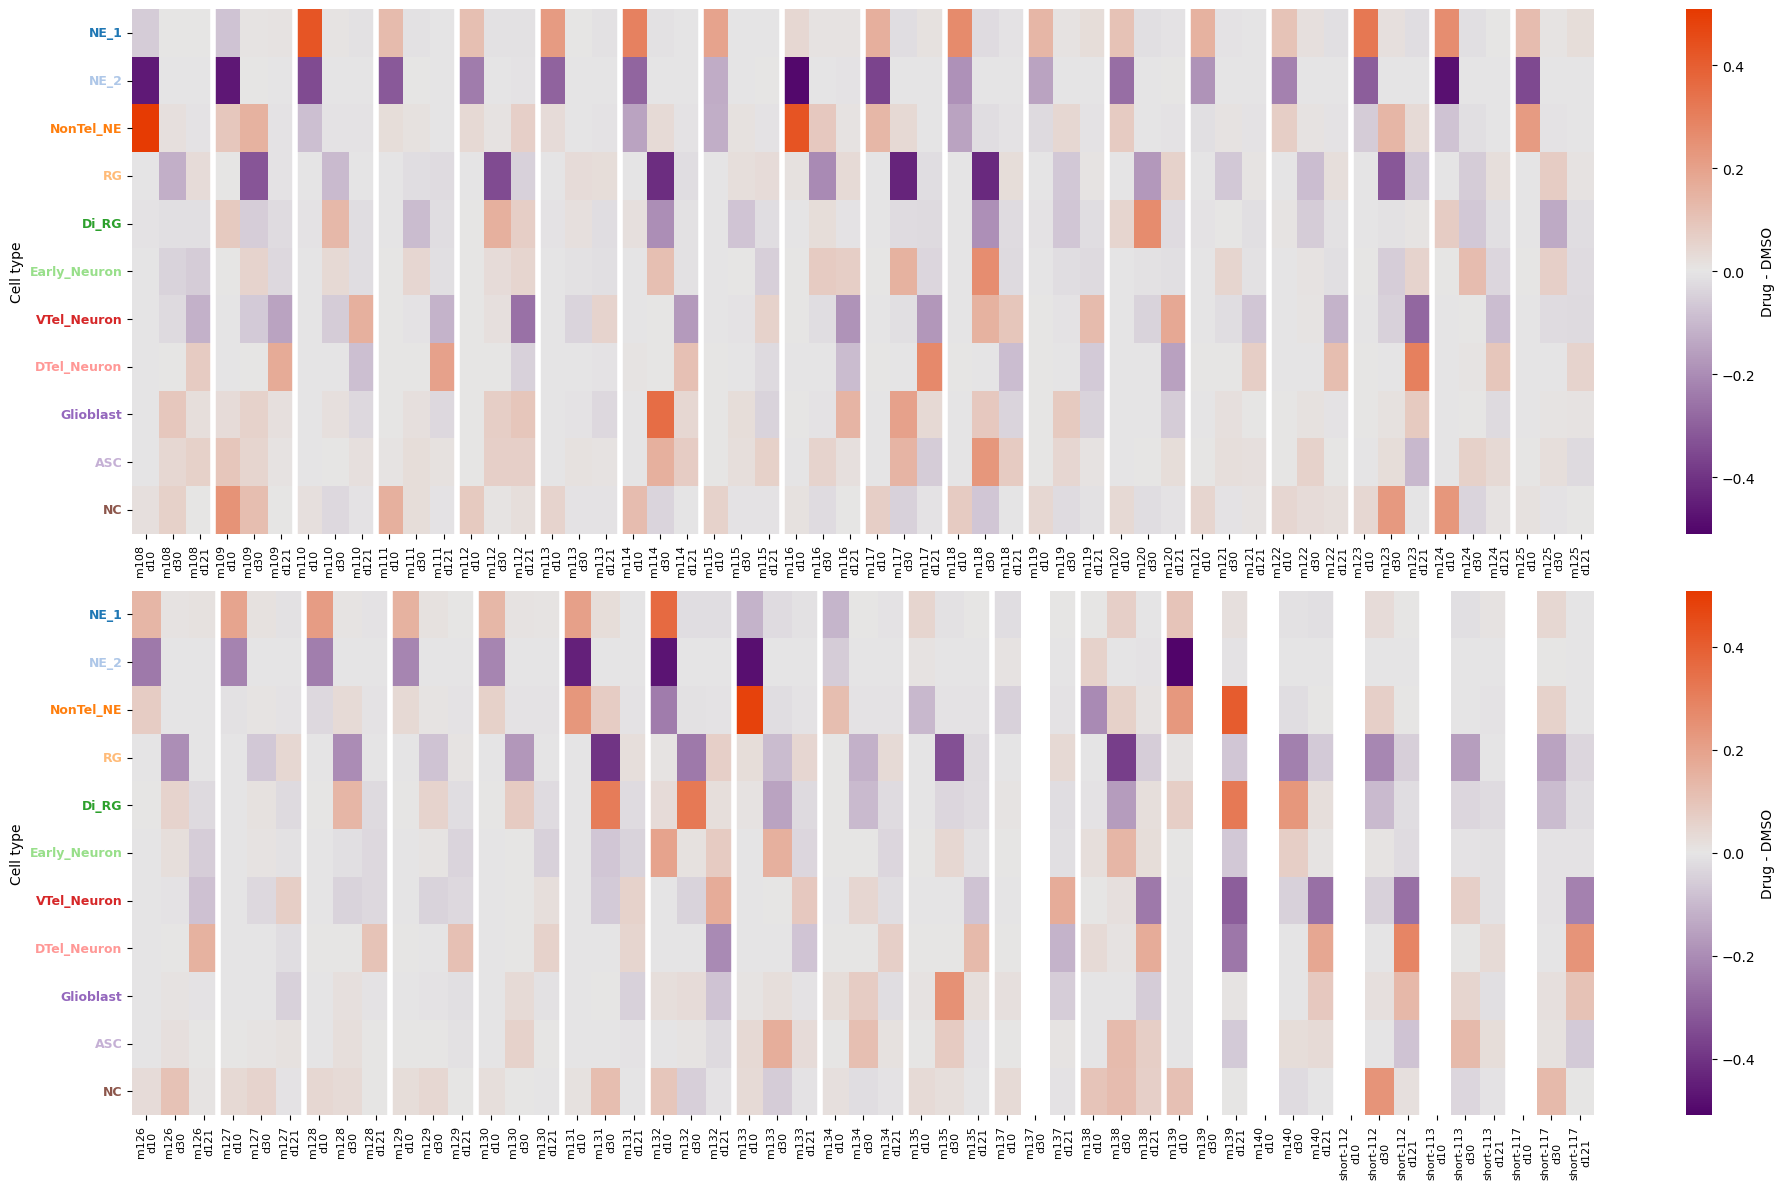

In [16]:
# Negative: purple; zero: light gray; positive: orange.
cmap = LinearSegmentedColormap.from_list(
    "figure2a_style",
    ["#51046A", "#E6E6E6", "#E63A01"],
    N=257,
)
cmap.set_bad("#FFFFFF")

# Use cell types from the index, not the displayed tick text.
if isinstance(plot_data.index, pd.MultiIndex):
    celltypes = plot_data.index.get_level_values(
        "celltype_scANVI_confident"
    )
else:
    celltypes = plot_data.index

unique_celltypes = celltypes.unique()
celltype_colors = dict(zip(
    unique_celltypes,
    sns.color_palette("tab20", n_colors=len(unique_celltypes)),
))

split = (len(drugs) + 1) // 2
drug_groups = [drugs[:split], drugs[split:]]
n_timepoints = len(timepoints)

fig, axes = plt.subplots(
    2, 1,
    figsize=(max(12, split * 1.1), 12),
)

for ax, group in zip(axes, drug_groups):
    columns = pd.MultiIndex.from_product([group, timepoints])
    data = plot_data.reindex(columns=columns)

    sns.heatmap(
        data,
        cmap=cmap,
        center=0,
        vmin=-limit,
        vmax=limit,
        xticklabels=[
            f"{drug}\n{timepoint}"
            for drug, timepoint in data.columns
        ],
        yticklabels=True,
        cbar_kws={"label": "Drug - DMSO"},
        ax=ax,
    )

    for label, celltype in zip(ax.get_yticklabels(), celltypes):
        label.set_color(celltype_colors[celltype])
        label.set_fontweight("bold")

    for x in range(n_timepoints, data.shape[1], n_timepoints):
        ax.axvline(x, color="white", linewidth=4, zorder=3)

    ax.set_xlabel("")
    ax.set_ylabel("Cell type")
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=9)

plt.savefig(
    "/home/jiafzhou/GRN_org/figures/drug_celltype_depletion_enrichment.pdf",
    bbox_inches="tight",)

plt.savefig(
    "/home/jiafzhou/GRN_org/figures/drug_celltype_depletion_enrichment.png",
    bbox_inches="tight",)


plt.tight_layout()
plt.show()


inspect pooled loom file

In [1]:
from pathlib import Path
import h5py
import pandas as pd

In [2]:
project = Path("/home/jiafzhou/GRN_org")
results = project / "results"
pooled_file = results / "_pooled_reference_allcells/pooled_allcells.loom"

In [3]:
expected_drugs = list(dict.fromkeys(
    line.strip()
    for line in (project / "config/included_drugs.txt").read_text().splitlines()
    if line.strip()
))

expected_drugs

['m124',
 'm127',
 'm121',
 'm122',
 'm126',
 'm128',
 'm120',
 'm138',
 'm130',
 'm114',
 'm108',
 'm125',
 'm119',
 'm113',
 'm133',
 'm135',
 'm112',
 'm129',
 'm116',
 'm123',
 'm110',
 'dmso',
 'm131',
 'm115',
 'm134',
 'm111',
 'm132',
 'm117',
 'm140',
 'short-117',
 'short-113',
 'm118',
 'short-112',
 'm109']

In [4]:
# Count cells for each drug in the pooled Loom
with h5py.File(pooled_file, "r") as f:
    n_genes, n_cells = f["matrix"].shape
    drugs = f["col_attrs/Drug"].asstr()[:]

pooled_counts = pd.Series(drugs).value_counts()

pooled_counts

dmso         4736
m120         4625
m127         4577
m113         4521
m110         4477
m129         4464
m112         4459
m140         4458
m130         4414
m115         4409
m128         4386
m125         4374
m111         4372
m132         4370
m133         4354
m121         4354
m126         4353
m123         4327
m119         4316
m122         4291
m124         4278
m108         4265
m117         4213
m134         4200
m131         4186
m135         4127
m114         4031
m116         3858
short-117    3463
m138         3420
short-113    3230
m118         2731
short-112    2720
m109         2245
Name: count, dtype: int64

In [5]:
# Compare against each original input Loom
input_counts = {}
for drug in expected_drugs:
    with h5py.File(results / drug / "input.loom", "r") as f:
        input_counts[drug] = f["matrix"].shape[1]

check = pd.DataFrame({
    "input_cells": pd.Series(input_counts),
    "pooled_cells": pooled_counts.reindex(expected_drugs, fill_value=0),
})
check.index.name = "drug"
check["match"] = check["input_cells"].eq(check["pooled_cells"])

missing = sorted(set(expected_drugs) - set(pooled_counts.index))
unexpected = sorted(set(pooled_counts.index) - set(expected_drugs))

print(check.to_string())
print(f"\nPooled shape: {n_genes} genes × {n_cells} cells")
print("Missing drugs:", missing)
print("Unexpected drugs:", unexpected)

assert len(drugs) == n_cells, "Drug metadata length differs from matrix columns"
assert not missing and not unexpected, "Drug list does not match"
assert check["match"].all(), "Some drug cell counts do not match"
print("\nPASS: all expected drugs included; all cell counts match.")

           input_cells  pooled_cells  match
drug                                       
m124              4278          4278   True
m127              4577          4577   True
m121              4354          4354   True
m122              4291          4291   True
m126              4353          4353   True
m128              4386          4386   True
m120              4625          4625   True
m138              3420          3420   True
m130              4414          4414   True
m114              4031          4031   True
m108              4265          4265   True
m125              4374          4374   True
m119              4316          4316   True
m113              4521          4521   True
m133              4354          4354   True
m135              4127          4127   True
m112              4459          4459   True
m129              4464          4464   True
m116              3858          3858   True
m123              4327          4327   True
m110              4477          

In [6]:
check

,input_cells,pooled_cells,match
drug,,,
m124,4278,4278,True
m127,4577,4577,True
m121,4354,4354,True
m122,4291,4291,True
m126,4353,4353,True
m128,4386,4386,True
m120,4625,4625,True
m138,3420,3420,True
m130,4414,4414,True


In [8]:
adata_ds_clean = ad.read_h5ad("/home/jiafzhou/GRN_org/dataset/adata_hvg_dmso-treatment-combined_scANVI_umap_ds_clean.h5ad", backed="r")

In [10]:
adata = ad.read_h5ad("/home/jiafzhou/GRN_org/dataset/adata_hvg_dmso-treatment-combined_scANVI_umap.h5ad", backed="r")

In [11]:
pd.crosstab(adata.obs["drug"],
            adata.obs["timepoint"])

timepoint,d10,d30,d121
drug,,,
dmso,28057,15868,17659
m108,23607,20336,20646
m109,4083,2753,9792
m110,19600,16316,19750
m111,22166,12925,5203
m112,18964,18067,8352
m113,15380,18685,17721
m114,21127,20779,12081
m115,23208,14264,13977


In [9]:
pd.crosstab(adata_ds_clean.obs["drug"],
            adata_ds_clean.obs["timepoint"])

timepoint,d10,d30,d121
drug,,,
dmso,4628,4736,4730
m108,4399,4265,4467
m109,3064,2245,4533
m110,4183,4477,4634
m111,3908,4372,4691
m112,3953,4459,4524
m113,4048,4521,4609
m114,3910,4031,4625
m115,3876,4409,4608
